In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RESULTS = Path("..") / "results" / "timings.csv"
df = pd.read_csv(RESULTS)

df["us_per_op"] = df["total_ns"] / df["n_ops"] / 1_000

print("Loaded", len(df), "measurements")

Loaded 1695 measurements


In [2]:
e6 = df[
    (df["experiment"] == "E6_bplus_order") &
    (df["machine_id"] == "imani-mbp") &
    (df["session_id"] == "df4df9bf6992")
].copy()

print("E6 measurements:", len(e6))
print("Orders:", sorted(e6["index_param"].unique()))
print("Operations:", e6["operation"].unique())

E6 measurements: 225
Orders: ['order=128', 'order=16', 'order=256', 'order=3', 'order=32', 'order=4', 'order=512', 'order=64', 'order=8']
Operations: ['build' 'point_hit' 'point_miss' 'range']


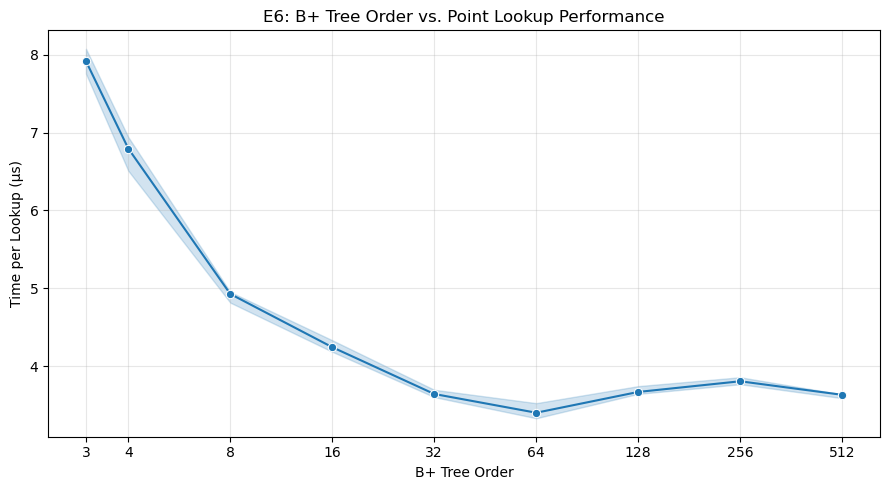

In [4]:
# Extract the numeric B+ tree order
e6["order"] = e6["index_param"].str.replace("order=", "").astype(int)

# Keep only successful point lookups
hits = e6[e6["operation"] == "point_hit"]

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=hits,
    x="order",
    y="us_per_op",
    estimator="median",
    errorbar=("pi", 50),
    marker="o"
)

plt.xscale("log", base=2)
plt.xlabel("B+ Tree Order")
plt.ylabel("Time per Lookup (µs)")
plt.title("E6: B+ Tree Order vs. Point Lookup Performance")
plt.xticks(sorted(e6["order"].unique()),
           sorted(e6["order"].unique()))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("e6_point_lookup_postfix.png", dpi=300, bbox_inches="tight")
plt.show()

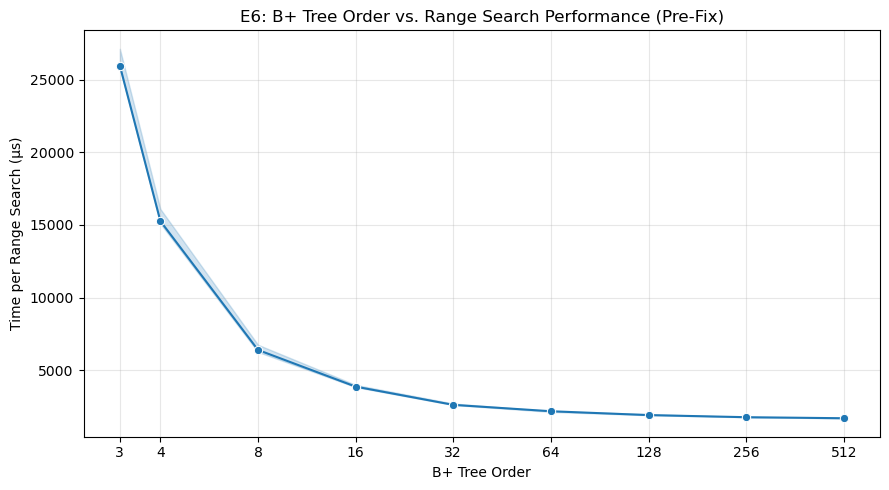

In [5]:
# Filter E6 range-search measurements
ranges = e6[e6["operation"] == "range"]

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=ranges,
    x="order",
    y="us_per_op",
    estimator="median",
    errorbar=("pi", 50),
    marker="o"
)

plt.xscale("log", base=2)
plt.xticks(sorted(e6["order"].unique()),
           sorted(e6["order"].unique()))

plt.xlabel("B+ Tree Order")
plt.ylabel("Time per Range Search (µs)")
plt.title("E6: B+ Tree Order vs. Range Search Performance (Pre-Fix)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("e6_range_search_postfix.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:

before_id = "9c12510126aa"
after_id = "4e62119aa32b"

comparison = df[
    (df["experiment"] == "CORE") &
    (df["machine_id"] == "imani-mbp") &
    (df["session_id"].isin([before_id, after_id])) &
    (df["index_type"] == "bplus_tree")
].copy()

comparison["version"] = comparison["session_id"].map({
    before_id: "Before Fix",
    after_id: "After Fix"
})

print(comparison.groupby(["version", "operation"]).size())

version     operation 
After Fix   build         10
            point_hit      5
            point_miss     5
            prefix         5
            range          5
Before Fix  build         10
            point_hit      5
            point_miss     5
            prefix         5
            range          5
dtype: int64


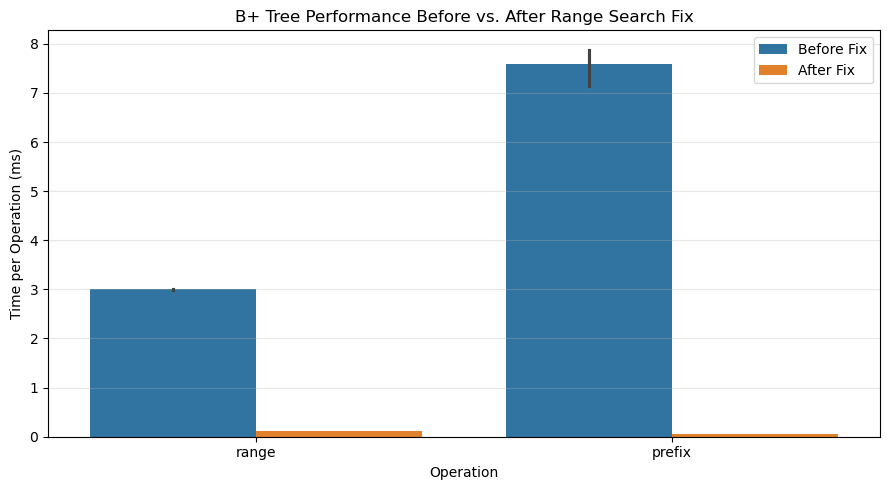

In [9]:
# Focus on the operations affected by the bug fix
fix_results = comparison[
    comparison["operation"].isin(["range", "prefix"])
].copy()

# Convert microseconds to milliseconds
fix_results["ms_per_op"] = fix_results["us_per_op"] / 1000

plt.figure(figsize=(9, 5))

sns.barplot(
    data=fix_results,
    x="operation",
    y="ms_per_op",
    hue="version",
    estimator="median",
    errorbar=("pi", 50),
    hue_order=["Before Fix", "After Fix"]
)

plt.xlabel("Operation")
plt.ylabel("Time per Operation (ms)")
plt.title("B+ Tree Performance Before vs. After Range Search Fix")
plt.legend(title="")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("bplus_before_after.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
hardware = df[
    (df["experiment"] == "CORE") &
    (df["machine_id"].isin(["imani-mbp", "saariya-mbp"]))
].copy()

print(
    hardware.groupby(
        ["machine_id", "session_id", "code_version"]
    ).size()
)

machine_id   session_id    code_version 
imani-mbp    4e62119aa32b  7d98672-dirty    210
             9c12510126aa  7d98672-dirty    210
saariya-mbp  34a86f3af90e  7e96499          210
dtype: int64


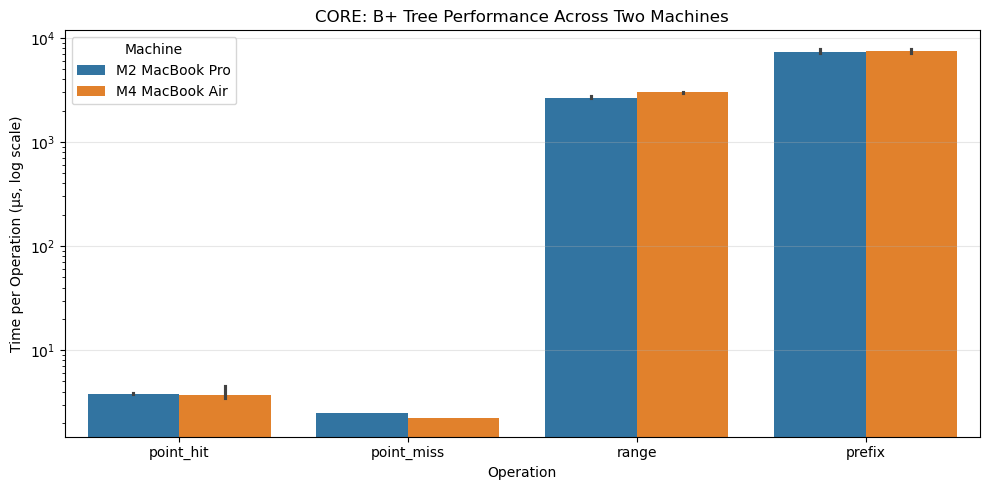

In [11]:
# Select one CORE session from each machine
hardware = df[
    (df["experiment"] == "CORE") &
    (
        ((df["machine_id"] == "imani-mbp") &
         (df["session_id"] == "9c12510126aa")) |
        ((df["machine_id"] == "saariya-mbp") &
         (df["session_id"] == "34a86f3af90e"))
    ) &
    (df["index_type"] == "bplus_tree") &
    (df["operation"].isin(["point_hit", "point_miss", "range", "prefix"]))
].copy()

hardware["machine"] = hardware["machine_id"].map({
    "imani-mbp": "M4 MacBook Air",
    "saariya-mbp": "M2 MacBook Pro"
})

plt.figure(figsize=(10, 5))

sns.barplot(
    data=hardware,
    x="operation",
    y="us_per_op",
    hue="machine",
    estimator="median",
    errorbar=("pi", 50)
)

plt.yscale("log")
plt.xlabel("Operation")
plt.ylabel("Time per Operation (µs, log scale)")
plt.title("CORE: B+ Tree Performance Across Two Machines")
plt.legend(title="Machine")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("hardware_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
ls analysis/*.png